# Сравнение macro-F1 и weighted-F1

Индивидуальное задание №22. Тема: сравнение macro-F1 и weighted-F1 при многоклассовой классификации.

## 1. Постановка задачи и метрики

**Цель.** Выяснить, чем macro-F1 и weighted-F1 отличаются друг от друга: когда их значения близки, когда расходятся и как это влияет на оценку классификатора.

В работе строго разделяются два типа утверждений:

- **математические свойства метрик** — следуют из формул и проверяются на заданных матрицах ошибок, без обучения моделей (разделы 2 и 3);
- **результаты обучения моделей** — зависят от данных и алгоритмов, поэтому всегда относятся к конкретному набору данных и протоколу оценки.

### Определения

Пусть классов $K$, а $C_{ij}$ — число объектов истинного класса $i$, предсказанных как класс $j$. Для класса $k$:

$$
TP_k = C_{kk},\qquad
FP_k = \sum_{i \ne k} C_{ik},\qquad
FN_k = \sum_{j \ne k} C_{kj},\qquad
n_k = TP_k + FN_k,\qquad N = \sum_k n_k .
$$

Величина $n_k$ — *support*, число объектов класса $k$ среди истинных меток. Доля класса: $p_k = n_k / N$.

$$
\text{precision}_k = \frac{TP_k}{TP_k + FP_k},\qquad
\text{recall}_k = \frac{TP_k}{TP_k + FN_k},\qquad
F1_k = \frac{2\,\text{precision}_k\,\text{recall}_k}{\text{precision}_k + \text{recall}_k} = \frac{2\,TP_k}{2\,TP_k + FP_k + FN_k}.
$$

Итоговые метрики — два способа усреднить один и тот же вектор $(F1_1, \dots, F1_K)$:

$$
\text{macro-F1}\;(M) = \frac1K \sum_{k=1}^{K} F1_k,\qquad
\text{weighted-F1}\;(W) = \sum_{k=1}^{K} p_k\,F1_k .
$$

### Роль support

В macro-F1 все классы равноправны, размер класса не учитывается. В weighted-F1 вес класса равен его доле в **истинных** метках, а не среди предсказаний. Поэтому weighted-F1 близок по смыслу к усреднению по объектам: частые классы определяют итог, редкие почти не слышны.

### Тождество для разности метрик

Так как $\sum_k (p_k - 1/K) = 0$, из $F1_k$ можно вычесть любую константу, не изменив сумму:

$$
W - M = \sum_{k=1}^{K} \left(p_k - \frac1K\right) F1_k = K \cdot \operatorname{Cov}_k\!\left(p_k,\, F1_k\right),
$$

где ковариация берётся по классам. Слагаемое $(p_k - 1/K)\,F1_k$ назовём *вкладом класса $k$* в разность. Следствия:

1. Если support всех классов равны, то $W = M$ при любых предсказаниях.
2. Если у всех классов одинаковый $F1_k$, то $W = M$.
3. Знак разности зависит от того, лучше или хуже распознаются частые классы. $W > M$ — если лучше, $W < M$ — если хуже. Неравенство $W \ge M$ не является законом.

### Нулевые знаменатели

$F1_k = 2TP_k / (2TP_k + FP_k + FN_k)$ не определён только если $TP_k = FP_k = FN_k = 0$, то есть класс отсутствует и в истинных метках, и в предсказаниях. В остальных случаях он определён, в том числе равен 0, если класс ни разу не предсказан. Для неопределённых значений принято `zero_division = 0`, как в sklearn по умолчанию. Набор меток всегда задаётся явно, чтобы $K$ не зависел от того, какие классы встретились в данных.

### Собственная реализация и сверка

Метрики реализованы на NumPy в модуле `f1_metrics.py` и не используют sklearn:

- `confusion_matrix` — матрица ошибок для явного набора меток;
- `summarize_confusion_matrix` — все показатели по готовой матрице (подходит и для заданных вручную матриц);
- `f1_report` — то же по векторам меток; `macro_f1`, `weighted_f1` — краткие обёртки.

Файл `test_f1_metrics.py` сверяет модуль со sklearn на 2000 воспроизводимых случайных примерах (среди них есть классы, отсутствующие в `y_true` или `y_pred`) при явных `zero_division=0` и `labels`, а также проверяет граничные случаи и тождество для $W - M$. Ячейка ниже запускает проверку.

In [1]:
import platform

import matplotlib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

from f1_metrics import summarize_confusion_matrix
import test_f1_metrics

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(f"Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, "
      f"matplotlib {matplotlib.__version__}, scikit-learn {sklearn.__version__}")

Python 3.11.5, numpy 2.4.6, pandas 3.1.1, matplotlib 3.11.2, scikit-learn 1.9.1


In [2]:
test_f1_metrics.main()

ok   test_class_absent_from_both_but_in_labels
ok   test_class_absent_from_predictions
ok   test_class_absent_from_true
ok   test_confusion_matrix_layout_and_label_order
ok   test_equal_support_gives_equal_macro_and_weighted
ok   test_gap_identity
ok   test_imbalanced_majority_classifier
ok   test_input_validation
ok   test_perfect_and_worst_predictions
ok   test_random_cases_match_sklearn
ok   test_weighted_below_macro
ok   test_wrappers_agree_with_report

Пройдено тестов: 12 из 12
Сравнений со sklearn: 2012 (из них случайных: 2000)
Случайные примеры с классом, отсутствующим в y_true: 537, в y_pred: 355
Максимальное абсолютное расхождение со sklearn: 3.331e-16


Дальше все метрики считаются только функциями из `f1_metrics.py`. sklearn используется исключительно для сверки.

In [3]:
def expand(cm, labels):
    # векторы меток, порождающие заданную целочисленную матрицу ошибок
    rows, cols = np.indices(cm.shape)
    counts = cm.ravel()
    return np.repeat(labels[rows.ravel()], counts), np.repeat(labels[cols.ravel()], counts)


def sklearn_max_diff(cm):
    # максимальное расхождение нашего модуля и sklearn для матрицы ошибок cm
    labels = np.arange(cm.shape[0])
    y_true, y_pred = expand(cm, labels)
    ours = summarize_confusion_matrix(cm)
    kw = {"labels": labels, "zero_division": 0}
    return max(
        np.abs(ours["f1"] - f1_score(y_true, y_pred, average=None, **kw)).max(),
        abs(ours["macro_f1"] - f1_score(y_true, y_pred, average="macro", **kw)),
        abs(ours["weighted_f1"] - f1_score(y_true, y_pred, average="weighted", **kw)),
        abs(ours["accuracy"] - accuracy_score(y_true, y_pred)),
    )


def clean(x, tol=1e-12):
    # убирает машинный шум вида -1e-17 при выводе
    return 0.0 if abs(x) < tol else float(x)

## 2. Эксперимент E1a — показательные случаи

**Что проверяем.** Как ведут себя $M$ и $W$ на трёх специально сконструированных матрицах ошибок. Это не результаты обучения моделей: матрицы заданы вручную, чтобы показать свойства метрик в чистом виде.

1. **A.** Классификатор всегда предсказывает большинство; доли классов 95/5.
2. **B.** Три класса с одинаковым support, но с разным качеством распознавания.
3. **C.** Два крупных класса, которые путаются между собой, и один редкий, распознанный безошибочно.

In [4]:
cases = {
    "A. Всегда большинство (95/5)": (
        np.array([[950, 0], [50, 0]]), ["большинство", "редкий"]),
    "B. Равные классы с ошибками": (
        np.array([[90, 5, 5], [20, 70, 10], [10, 30, 60]]), ["класс 1", "класс 2", "класс 3"]),
    "C. Крупные трудные + редкий лёгкий": (
        np.array([[200, 200, 0], [200, 200, 0], [0, 0, 20]]), ["крупный 1", "крупный 2", "редкий"]),
}
reports = {name: summarize_confusion_matrix(cm) for name, (cm, _) in cases.items()}


def show_case(name):
    cm, classes = cases[name]
    r = reports[name]
    print(name)
    display(pd.DataFrame(cm, index=pd.Index(classes, name="истинный класс"),
                         columns=pd.Index(classes, name="предсказанный")))
    display(pd.DataFrame({
        "support": r["support"], "precision": r["precision"], "recall": r["recall"],
        "F1": r["f1"], "вклад (p_k − 1/K)·F1_k": r["gap_contributions"] + 0.0,
    }, index=classes))
    print(f"accuracy = {r['accuracy']:.4f}   macro-F1 = {r['macro_f1']:.4f}   "
          f"weighted-F1 = {r['weighted_f1']:.4f}   W − M = {clean(r['gap']):+.4f}")

### Случай A: всегда большинство

In [5]:
show_case("A. Всегда большинство (95/5)")

A. Всегда большинство (95/5)


предсказанный,большинство,редкий
истинный класс,,
большинство,950,0
редкий,50,0


,support,precision,recall,F1,вклад (p_k − 1/K)·F1_k
большинство,950,0.95,1.0,0.9744,0.4385
редкий,50,0.00,0.0,0.0000,0.0000


accuracy = 0.9500   macro-F1 = 0.4872   weighted-F1 = 0.9256   W − M = +0.4385


Accuracy равна 0.95, хотя редкий класс не распознан ни разу. Precision редкого класса — это $0/0$ (класс не предсказывался), принято значение 0, но $F1$ при этом определён и равен нулю ($TP=0$, $FN=50$). Поэтому macro-F1 вдвое меньше $F1$ большинства и составляет 0.4872. Weighted-F1 остаётся высоким (0.9256): вес редкого класса всего 0.05. Разность $W - M = 0.4385$ целиком создаётся большинством: $(0.95 - 0.5)\cdot 0.9744$.

### Случай B: равные support

In [6]:
show_case("B. Равные классы с ошибками")

B. Равные классы с ошибками


предсказанный,класс 1,класс 2,класс 3
истинный класс,,,
класс 1,90,5,5
класс 2,20,70,10
класс 3,10,30,60


,support,precision,recall,F1,вклад (p_k − 1/K)·F1_k
класс 1,100,0.7500,0.9,0.8182,0.0
класс 2,100,0.6667,0.7,0.6829,0.0
класс 3,100,0.8000,0.6,0.6857,0.0


accuracy = 0.7333   macro-F1 = 0.7289   weighted-F1 = 0.7289   W − M = +0.0000


У классов разные $F1_k$ (от 0.68 до 0.82), то есть равенство не связано с одинаковым качеством. Macro-F1 и weighted-F1 совпадают (0.7289), потому что $p_k = 1/K$ и все вклады равны нулю. Accuracy при этом другая (0.7333): weighted-F1 не равен accuracy даже при равных классах.

### Случай C: weighted-F1 меньше macro-F1

In [7]:
show_case("C. Крупные трудные + редкий лёгкий")

C. Крупные трудные + редкий лёгкий


предсказанный,крупный 1,крупный 2,редкий
истинный класс,,,
крупный 1,200,200,0
крупный 2,200,200,0
редкий,0,0,20


,support,precision,recall,F1,вклад (p_k − 1/K)·F1_k
крупный 1,400,0.5,0.5,0.5,0.0772
крупный 2,400,0.5,0.5,0.5,0.0772
редкий,20,1.0,1.0,1.0,-0.3089


accuracy = 0.5122   macro-F1 = 0.6667   weighted-F1 = 0.5122   W − M = -0.1545


Два крупных класса постоянно путаются между собой ($F1 = 0.5$), а редкий класс (2.4% объектов) распознан безошибочно ($F1 = 1$). Macro-F1 равен 0.6667 и выше weighted-F1 (0.5122): $W - M = -0.1545$. Отрицательный вклад редкого класса ($-0.3089$) не компенсируется положительными вкладами двух крупных ($+0.0772$ каждый). Weighted-F1 здесь почти целиком определяется двумя крупными классами.

Заметим, что в этой матрице weighted-F1 совпадает с accuracy (0.5122). Это частность: матрица симметрична, у каждого класса $FP_k = FN_k$, поэтому $\text{precision}_k = \text{recall}_k = F1_k$ и $\sum_k p_k F1_k = \sum_k TP_k / N$. В общем случае $W \ne \text{accuracy}$ (см. случаи A и B).

### Сводная таблица

In [8]:
summary = pd.DataFrame([
    {"случай": name, "K": len(r["support"]), "N": int(r["support"].sum()),
     "accuracy": r["accuracy"], "macro-F1": r["macro_f1"],
     "weighted-F1": r["weighted_f1"], "W − M": clean(r["gap"])}
    for name, r in reports.items()
]).set_index("случай")
summary

,K,N,accuracy,macro-F1,weighted-F1,W − M
случай,,,,,,
A. Всегда большинство (95/5),2,1000,0.9500,0.4872,0.9256,0.4385
B. Равные классы с ошибками,3,300,0.7333,0.7289,0.7289,0.0000
C. Крупные трудные + редкий лёгкий,3,820,0.5122,0.6667,0.5122,-0.1545


In [9]:
r_a, r_b, r_c = reports.values()

sk_diff = max(sklearn_max_diff(cm) for cm, _ in cases.values())
assert sk_diff < 1e-12

assert all(abs(r["gap"] - r["gap_contributions"].sum()) < 1e-12 for r in reports.values())

assert len(set(r_b["support"])) == 1 and abs(r_b["macro_f1"] - r_b["weighted_f1"]) < 1e-12
assert r_c["weighted_f1"] < r_c["macro_f1"]

f1_major = 2 * 950 / (2 * 950 + 50)
assert abs(r_a["macro_f1"] - f1_major / 2) < 1e-12
assert abs(r_a["weighted_f1"] - 0.95 * f1_major) < 1e-12
assert abs(r_c["weighted_f1"] - r_c["accuracy"]) < 1e-12

print(f"Максимальное расхождение со sklearn: {sk_diff:.2e}")
print("W − M равно сумме вкладов классов во всех трёх случаях")
print("B: support равны, macro-F1 = weighted-F1")
print("C: weighted-F1 < macro-F1")
print("A: значения совпали с расчётом по формулам вручную")

Максимальное расхождение со sklearn: 1.11e-16
W − M равно сумме вкладов классов во всех трёх случаях
B: support равны, macro-F1 = weighted-F1
C: weighted-F1 < macro-F1
A: значения совпали с расчётом по формулам вручную


### Выводы по E1a

- Accuracy и weighted-F1 в случае A остаются высокими (0.95 и 0.9256) у классификатора, который полностью игнорирует редкий класс. Macro-F1 (0.4872) эту проблему показывает.
- Равенство $M = W$ в случае B — следствие равных support, а не одинакового качества классов: $F1_k$ различаются, но вклады обнуляются.
- В случае C $W < M$: утверждение «weighted-F1 не ниже macro-F1» неверно. Знак разности определяется тем, какие классы распознаются лучше: частые или редкие.
- Разность $W - M$ во всех случаях совпала с суммой вкладов классов, а метрики собственного модуля — со sklearn.

## 3. Эксперимент E1b — влияние дисбаланса

**Вопрос.** Как меняются $M$ и $W$, если качество классификатора остаётся прежним, а доля редкого класса уменьшается?

**Постановка.** Бинарная классификация, класс 1 — редкий (положительный). Общее число объектов $N = 100\,000$, доля редкого класса $\pi$ меняется от 0.5% до 50%. Для редкого класса зафиксированы $\mathrm{TPR} = 0.8$ и $\mathrm{FPR} = 0.05$. Матрица ошибок вычисляется детерминированно, случайные предсказания не моделируются:

$$
TP = \mathrm{TPR}\cdot \pi N,\quad FN = (1-\mathrm{TPR})\,\pi N,\quad
FP = \mathrm{FPR}\cdot (1-\pi) N,\quad TN = (1-\mathrm{FPR})\,(1-\pi) N .
$$

Чтобы все элементы были целыми, число редких объектов берётся кратным 20. Сетка содержит доли 0.5%, 1%, 2%, 5%, 10%, 20%, 50% и дополнительные точки, равномерные по логарифму. Точка $\pi = 50\%$ — контрольная: классы равны, и $W = M$.

In [10]:
N = 100_000
TPR, FPR = 0.8, 0.05
nominal_shares = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5])

shares = np.union1d(nominal_shares, np.geomspace(0.005, 0.5, 40))
n_rare_grid = np.unique(20 * np.rint(shares * N / 20).astype(int))


def rare_class_matrix(n_rare):
    n_major = N - n_rare
    counts = np.array([
        [(1 - FPR) * n_major, FPR * n_major],
        [(1 - TPR) * n_rare, TPR * n_rare],
    ])
    cm = np.rint(counts).astype(int)
    assert np.allclose(counts, cm, rtol=0, atol=1e-8), "число объектов не целое"
    assert (cm >= 0).all() and cm.sum() == N
    return cm


matrices = {n: rare_class_matrix(n) for n in n_rare_grid}
reports_b = {n: summarize_confusion_matrix(cm) for n, cm in matrices.items()}

df = pd.DataFrame([
    {"n_rare": n, "share": n / N, "TP": cm[1, 1], "FP": cm[0, 1],
     "precision_rare": r["precision"][1], "recall_rare": r["recall"][1],
     "f1_rare": r["f1"][1], "f1_major": r["f1"][0],
     "macro_f1": r["macro_f1"], "weighted_f1": r["weighted_f1"],
     "accuracy": r["accuracy"], "gap": r["gap"]}
    for (n, cm), r in zip(matrices.items(), reports_b.values())
])
print(f"Точек сетки: {len(df)}, доля редкого класса от {df['share'].min():.1%} до {df['share'].max():.1%}")

Точек сетки: 45, доля редкого класса от 0.5% до 50.0%


In [11]:
nominal_n = (nominal_shares * N).astype(int)
table = df[df["n_rare"].isin(nominal_n)].copy()
table.index = [f"{s:g}%" for s in table["share"] * 100]
table.index.name = "доля редкого класса"
table[["TP", "FP", "precision_rare", "f1_rare", "f1_major", "macro_f1", "weighted_f1", "accuracy", "gap"]].rename(
    columns={"precision_rare": "precision редкого", "f1_rare": "F1 редкого", "f1_major": "F1 большинства",
             "macro_f1": "macro-F1", "weighted_f1": "weighted-F1", "gap": "W − M"})

,TP,FP,precision редкого,F1 редкого,F1 большинства,macro-F1,weighted-F1,accuracy,W − M
доля редкого класса,,,,,,,,,
0.5%,400,4975,0.0744,0.1362,0.9739,0.5550,0.9697,0.9493,0.4147
1%,800,4950,0.1391,0.2370,0.9734,0.6052,0.9660,0.9485,0.3608
2%,1600,4900,0.2462,0.3765,0.9723,0.6744,0.9604,0.9470,0.2860
5%,4000,4750,0.4571,0.5818,0.9691,0.7755,0.9498,0.9425,0.1743
10%,8000,4500,0.6400,0.7111,0.9634,0.8372,0.9382,0.9350,0.1009
20%,16000,4000,0.8000,0.8000,0.9500,0.8750,0.9200,0.9200,0.0450
50%,40000,2500,0.9412,0.8649,0.8837,0.8743,0.8743,0.8750,0.0000


In [12]:
# проверки E1b
pi = df["share"].to_numpy()
tpr_actual = np.array([cm[1, 1] / cm[1].sum() for cm in matrices.values()])
fpr_actual = np.array([cm[0, 1] / cm[0].sum() for cm in matrices.values()])
assert np.allclose(tpr_actual, TPR, rtol=0, atol=1e-12)
assert np.allclose(fpr_actual, FPR, rtol=0, atol=1e-12)

precision_theory = TPR * pi / (TPR * pi + FPR * (1 - pi))
f1_rare_theory = 2 * TPR * pi / ((1 + TPR) * pi + FPR * (1 - pi))
gap_theory = (0.5 - pi) * (df["f1_major"] - df["f1_rare"])
assert np.allclose(df["precision_rare"], precision_theory, rtol=0, atol=1e-12)
assert np.allclose(df["f1_rare"], f1_rare_theory, rtol=0, atol=1e-12)
assert np.allclose(df["gap"], gap_theory, rtol=0, atol=1e-12)

assert all(abs(r["gap"] - r["gap_contributions"].sum()) < 1e-12 for r in reports_b.values())
assert abs(df.loc[df["n_rare"] == N // 2, "gap"].iloc[0]) < 1e-12
assert df["gap"].is_monotonic_decreasing

sk_diff_b = max(sklearn_max_diff(cm) for cm in matrices.values())
assert sk_diff_b < 1e-12

print(f"Матрицы: целые, неотрицательные, сумма = {N} во всех {len(matrices)} точках")
print(f"Фактические TPR и FPR совпали с заданными (макс. отклонение "
      f"{max(abs(tpr_actual - TPR).max(), abs(fpr_actual - FPR).max()):.1e})")
print("precision, F1 редкого класса и W − M совпали с формулами (допуск 1e-12)")
print("W − M равна сумме вкладов классов; при доле 50% W − M = 0; по сетке W − M убывает с ростом доли")
print(f"Максимальное расхождение со sklearn: {sk_diff_b:.2e}")

Матрицы: целые, неотрицательные, сумма = 100000 во всех 45 точках
Фактические TPR и FPR совпали с заданными (макс. отклонение 0.0e+00)
precision, F1 редкого класса и W − M совпали с формулами (допуск 1e-12)
W − M равна сумме вкладов классов; при доле 50% W − M = 0; по сетке W − M убывает с ростом доли
Максимальное расхождение со sklearn: 2.22e-16


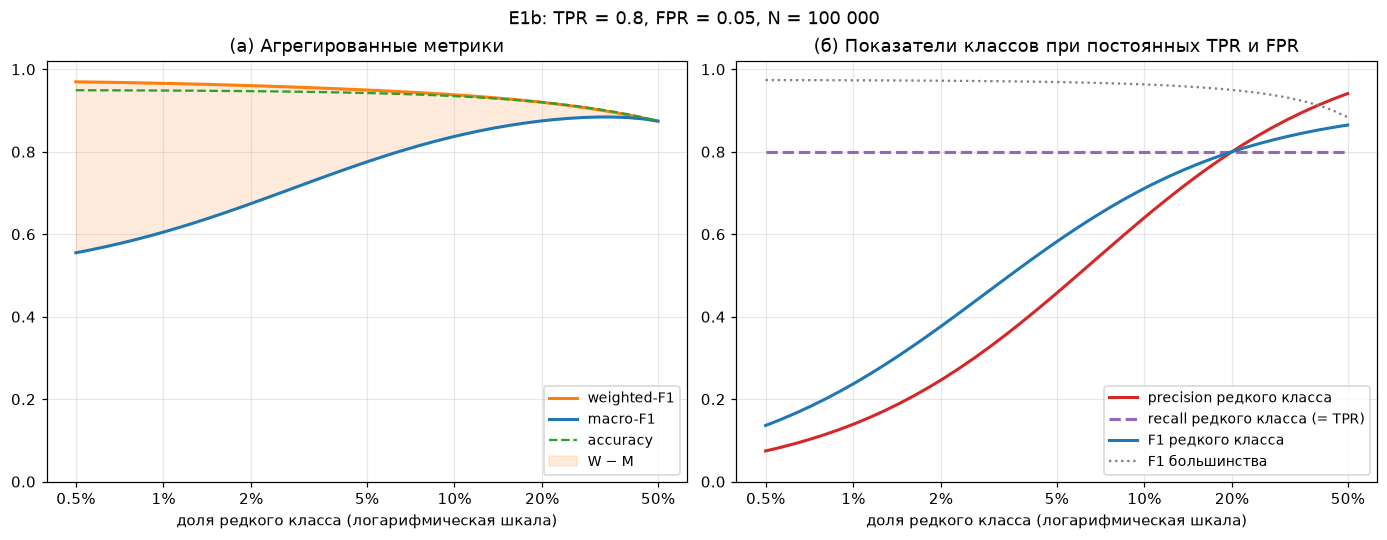

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
pct = df["share"] * 100

ax1.plot(pct, df["weighted_f1"], color="C1", lw=2, label="weighted-F1")
ax1.plot(pct, df["macro_f1"], color="C0", lw=2, label="macro-F1")
ax1.plot(pct, df["accuracy"], color="C2", lw=1.5, ls="--", label="accuracy")
ax1.fill_between(pct, df["macro_f1"], df["weighted_f1"], color="C1", alpha=0.15, label="W − M")
ax1.set_title("(а) Агрегированные метрики")

ax2.plot(pct, df["precision_rare"], color="C3", lw=2, label="precision редкого класса")
ax2.plot(pct, df["recall_rare"], color="C4", lw=2, ls="--", label="recall редкого класса (= TPR)")
ax2.plot(pct, df["f1_rare"], color="C0", lw=2, label="F1 редкого класса")
ax2.plot(pct, df["f1_major"], color="gray", lw=1.5, ls=":", label="F1 большинства")
ax2.set_title("(б) Показатели классов при постоянных TPR и FPR")

ticks = [0.5, 1, 2, 5, 10, 20, 50]
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}%" for t in ticks])
    ax.minorticks_off()
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("доля редкого класса (логарифмическая шкала)")
    ax.legend(loc="lower right", fontsize=9)
fig.suptitle(f"E1b: TPR = {TPR}, FPR = {FPR}, N = {N:,}".replace(f"{N:,}", f"{N:,}".replace(",", " ")), fontsize=12)
plt.show()

### Почему F1 редкого класса меняется при постоянных TPR и FPR

TPR и FPR описывают поведение классификатора **внутри** каждого класса и от доли классов не зависят. Но $F1$ строится из счётчиков $TP$, $FP$, $FN$, а они зависят от размера классов по-разному:

$$
TP = \mathrm{TPR}\cdot\pi N,\qquad FN = (1-\mathrm{TPR})\cdot\pi N,\qquad FP = \mathrm{FPR}\cdot(1-\pi)N .
$$

Число верных срабатываний и пропусков пропорционально $\pi$, а число ложных тревог — $(1-\pi)$. Поэтому recall редкого класса остаётся равным TPR, а precision по формуле Байеса падает вместе с $\pi$:

$$
\text{precision}_{\text{редк}} = \frac{\mathrm{TPR}\,\pi}{\mathrm{TPR}\,\pi + \mathrm{FPR}\,(1-\pi)},\qquad
F1_{\text{редк}} = \frac{2\,\mathrm{TPR}\,\pi}{(1+\mathrm{TPR})\,\pi + \mathrm{FPR}\,(1-\pi)} .
$$

При $\pi \to 0$ получается $F1_{\text{редк}} \approx 2\,\mathrm{TPR}\,\pi / \mathrm{FPR} \to 0$. Причина в том, что $F1$ не учитывает $TN$: огромное число правильно отвергнутых объектов большинства не засчитывается, зато 5% из них превращаются в ложные срабатывания, и их число растёт относительно числа редких объектов. Таким образом, $F1$, а вместе с ним и macro-F1 зависят не только от качества классификатора, но и от распространённости классов.

Для двух классов разность метрик имеет простой вид: $W - M = (\tfrac12 - \pi)\,(F1_{\text{больш}} - F1_{\text{редк}})$. Она равна нулю при $\pi = 1/2$ и растёт с дисбалансом, пока $F1$ большинства существенно выше $F1$ редкого класса. Формулы $F1_{\text{редк}}$, precision и $W - M$ проверены в ячейке выше численно.

### Выводы по E1b

- При $\pi = 50\%$ $M = W = 0.8743$ (accuracy 0.8750). При $\pi = 0.5\%$ macro-F1 падает до 0.5550, а weighted-F1 **растёт** до 0.9697 (accuracy 0.9493). То есть при том же классификаторе метрики меняются в противоположные стороны, а $W - M$ увеличивается с 0 до 0.4147.
- Причина в редком классе: precision падает с 0.9412 до 0.0744, $F1_{\text{редк}}$ — с 0.8649 до 0.1362, при неизменном recall 0.8. При $\pi = 0.5\%$ ложных срабатываний (4975) в 12 с лишним раз больше, чем верных (400).
- $F1$ большинства меняется мало (от 0.8837 до 0.9739), и weighted-F1 в основном следует за ним, потому что вес большинства растёт.
- Macro-F1 чувствительна к редким классам, но $F1$ зависит и от распространённости классов. Поэтому при сравнении macro-F1 на выборках с разными долями классов нужно учитывать, что часть различия создаёт сама распространённость: у одного и того же классификатора macro-F1 равна 0.5550 при доле 0.5% и 0.8743 при доле 50%.
- Ни одну метрику нельзя назвать «правильной» вообще: weighted-F1 отвечает на вопрос о качестве в среднем по объектам, macro-F1 — в среднем по классам. Выбор зависит от того, как соотносится цена ошибок на редких и частых классах.

**Ограничения.** E1 — детерминированные сконструированные примеры. Они показывают свойства формул при заданных TPR и FPR, но не говорят, как ведут себя реальные обученные модели. Это проверяется в следующих разделах на данных.

## 4. Эксперимент E2 — обучение моделей на наборе wine

**Вопрос.** Как macro-F1 и weighted-F1 ведут себя на обученных моделях при умеренном естественном дисбалансе и меняют ли они оценку моделей?

**Данные.** `load_wine` из sklearn: 178 объектов, 13 признаков, 3 класса. Данные встроены в sklearn, скачивать ничего не нужно. Дисбаланс умеренный, поэтому сильного расхождения метрик здесь заранее не ожидается, а полученные результаты будут объяснены такими, какие они есть.

**Модели** заданы заранее, параметры не подбирались:

1. `Dummy` — `DummyClassifier(strategy="most_frequent")`, базовый ориентир;
2. `LogReg` — `StandardScaler` и `LogisticRegression` с параметрами по умолчанию в одном `Pipeline`;
3. `Tree` — `DecisionTreeClassifier(max_depth=3, random_state=42)`.

**Протокол.** Предсказания получены через `cross_val_predict` со `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`: каждый объект предсказывается моделью, которая его не видела. Масштабирование внутри `Pipeline` обучается только на обучающих частях каждого разбиения, поэтому утечки из тестовой части нет. Метрики считаются один раз по всем 178 объединённым предсказаниям, а не усреднением по частям. Используется одно разбиение, поэтому разброс результатов по другим разбиениям не оценивается.

In [14]:
from sklearn.datasets import load_wine
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from f1_metrics import f1_report

wine = load_wine()
X, y = wine.data, wine.target
class_names = [str(name) for name in wine.target_names]
labels = np.arange(len(class_names))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression()),
    "Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
}

predictions = {name: cross_val_predict(model, X, y, cv=cv) for name, model in models.items()}
reports_w = {name: f1_report(y, pred, labels) for name, pred in predictions.items()}

support = np.bincount(y)
print(f"Объектов: {X.shape[0]}, признаков: {X.shape[1]}, классов: {len(labels)}")
print("Support классов:", dict(zip(class_names, support.tolist())))
print("Доли классов:", dict(zip(class_names, np.round(support / support.sum(), 4).tolist())))

Объектов: 178, признаков: 13, классов: 3
Support классов: {'class_0': 59, 'class_1': 71, 'class_2': 48}
Доли классов: {'class_0': 0.3315, 'class_1': 0.3989, 'class_2': 0.2697}


In [15]:
summary_w = pd.DataFrame([
    {"модель": name, "accuracy": r["accuracy"], "macro-F1": r["macro_f1"],
     "weighted-F1": r["weighted_f1"], "W − M": r["gap"]}
    for name, r in reports_w.items()
]).set_index("модель")
summary_w["ранг по macro-F1"] = summary_w["macro-F1"].rank(ascending=False).astype(int)
summary_w["ранг по weighted-F1"] = summary_w["weighted-F1"].rank(ascending=False).astype(int)
summary_w

,accuracy,macro-F1,weighted-F1,W − M,ранг по macro-F1,ранг по weighted-F1
модель,,,,,,
Dummy,0.3989,0.1901,0.2275,0.0374,3,3
LogReg,0.9831,0.9826,0.9832,0.0006,1,1
Tree,0.8764,0.8794,0.8768,-0.0026,2,2


In [16]:
per_class = pd.DataFrame({"support": support, "доля p_k": support / support.sum()}, index=class_names)
contributions = pd.DataFrame(index=class_names)
for name, r in reports_w.items():
    per_class[f"F1 {name}"] = r["f1"]
    contributions[name] = r["gap_contributions"] + 0.0
contributions.loc["сумма = W − M"] = contributions.sum()

print("Support и F1 по классам")
display(per_class)
print("Вклады классов (p_k − 1/K)·F1_k в разность W − M")
display(contributions)

Support и F1 по классам


,support,доля p_k,F1 Dummy,F1 LogReg,F1 Tree
class_0,59,0.3315,0.0000,1.0000,0.9043
class_1,71,0.3989,0.5703,0.9787,0.8472
class_2,48,0.2697,0.0000,0.9691,0.8866


Вклады классов (p_k − 1/K)·F1_k в разность W − M


,Dummy,LogReg,Tree
class_0,0.0000,-0.0019,-0.0017
class_1,0.0374,0.0641,0.0555
class_2,0.0000,-0.0617,-0.0565
сумма = W − M,0.0374,0.0006,-0.0026


In [17]:
for name in ("LogReg", "Tree"):
    print(name)
    display(pd.DataFrame(reports_w[name]["confusion_matrix"],
                         index=pd.Index(class_names, name="истинный класс"),
                         columns=pd.Index(class_names, name="предсказанный")))

LogReg


предсказанный,class_0,class_1,class_2
истинный класс,,,
class_0,59,0,0
class_1,0,69,2
class_2,0,1,47


Tree


предсказанный,class_0,class_1,class_2
истинный класс,,,
class_0,52,7,0
class_1,4,61,6
class_2,0,5,43


In [18]:
from sklearn.metrics import confusion_matrix as sk_confusion_matrix


def max_diff_vs_sklearn(y_true, y_pred, report):
    kw = {"labels": labels, "zero_division": 0}
    np.testing.assert_array_equal(report["confusion_matrix"], sk_confusion_matrix(y_true, y_pred, labels=labels))
    return max(
        np.abs(report["f1"] - f1_score(y_true, y_pred, average=None, **kw)).max(),
        abs(report["macro_f1"] - f1_score(y_true, y_pred, average="macro", **kw)),
        abs(report["weighted_f1"] - f1_score(y_true, y_pred, average="weighted", **kw)),
        abs(report["accuracy"] - accuracy_score(y_true, y_pred)),
    )


# сверка со sklearn при одинаковых labels и zero_division=0
sk_diff_w = max(max_diff_vs_sklearn(y, predictions[name], r) for name, r in reports_w.items())
assert sk_diff_w < 1e-12

# тождество для разности метрик
p_k = support / support.sum()
for r in reports_w.values():
    assert abs(r["gap"] - r["gap_contributions"].sum()) < 1e-12
    assert abs(r["gap"] - len(labels) * np.mean((p_k - p_k.mean()) * (r["f1"] - r["f1"].mean()))) < 1e-12

# Dummy: значения следуют из формул
major = int(np.argmax(support))
f1_major = 2 * support[major] / (support[major] + len(y))
r_dummy = reports_w["Dummy"]
assert set(predictions["Dummy"]) == {major}
assert abs(r_dummy["accuracy"] - support[major] / len(y)) < 1e-12
assert abs(r_dummy["macro_f1"] - f1_major / len(labels)) < 1e-12
assert abs(r_dummy["weighted_f1"] - support[major] / len(y) * f1_major) < 1e-12
undefined = [class_names[k] for k in labels if r_dummy["tp"][k] + r_dummy["fp"][k] == 0]

# корректность разбиения: каждый объект ровно один раз в тестовой части, все классы в каждой части
test_parts = [test for _, test in cv.split(X, y)]
assert np.array_equal(np.sort(np.concatenate(test_parts)), np.arange(len(y)))
min_per_class = np.min([np.bincount(y[t], minlength=len(labels)) for t in test_parts], axis=0)
assert (min_per_class > 0).all()

# воспроизводимость: повторное обучение даёт те же предсказания
for name in ("LogReg", "Tree"):
    assert np.array_equal(cross_val_predict(models[name], X, y, cv=cv), predictions[name])

ranks_equal = (summary_w["ранг по macro-F1"] == summary_w["ранг по weighted-F1"]).all()

print(f"Максимальное расхождение со sklearn (матрица ошибок, F1 по классам, macro, weighted, accuracy): {sk_diff_w:.2e}")
print("W − M равна сумме вкладов и K·Cov(p, F1) для всех моделей")
print(f"Dummy: всегда предсказывает класс {class_names[major]}; accuracy, macro и weighted совпали с формулами")
print(f"Dummy: precision не определена (0/0, принято 0) для классов {undefined}; F1 этих классов определён и равен 0")
print("Разбиения: тестовые части не пересекаются и покрывают все 178 объектов; "
      f"минимум объектов класса в тестовой части: {dict(zip(class_names, min_per_class.tolist()))}")
print("Повторное обучение LogReg и Tree даёт те же предсказания")
print(f"Порядок моделей по macro-F1 и weighted-F1 совпадает: {bool(ranks_equal)}")

Максимальное расхождение со sklearn (матрица ошибок, F1 по классам, macro, weighted, accuracy): 2.22e-16
W − M равна сумме вкладов и K·Cov(p, F1) для всех моделей
Dummy: всегда предсказывает класс class_1; accuracy, macro и weighted совпали с формулами
Dummy: precision не определена (0/0, принято 0) для классов ['class_0', 'class_2']; F1 этих классов определён и равен 0
Разбиения: тестовые части не пересекаются и покрывают все 178 объектов; минимум объектов класса в тестовой части: {'class_0': 11, 'class_1': 14, 'class_2': 9}
Повторное обучение LogReg и Tree даёт те же предсказания
Порядок моделей по macro-F1 и weighted-F1 совпадает: True


### Результаты и анализ E2

**Общая картина.** Оба показателя упорядочивают модели одинаково: LogReg, затем Tree, затем Dummy. У обученных моделей macro-F1 и weighted-F1 почти совпадают: у LogReg 0.9826 и 0.9832 ($W - M = +0.0006$), у дерева 0.8794 и 0.8768 ($W - M = -0.0026$). Разница между самими моделями (около 0.10–0.11 по всем показателям) в десятки раз больше разницы между метриками.

**Почему разность мала.** По тождеству $W - M = K \cdot \operatorname{Cov}(p_k, F1_k)$ разность мала, если доли классов близки к $1/K$ или $F1$ классов близки друг к другу. Здесь доли классов 0.331, 0.399 и 0.270, то есть отклонения от $1/3$ не превышают 0.07, а у LogReg $F1$ классов лежат в узком диапазоне от 0.969 до 1.0. Вклады классов в разность почти компенсируют друг друга: у LogReg $+0.0641$ у класса 1, $-0.0617$ у класса 2 и $-0.0019$ у класса 0.

**LogReg.** Всего 3 ошибки на 178 объектов (два объекта класса 1 отнесены к классу 2 и один объект класса 2 — к классу 1), класс 0 распознан безошибочно. Для масштаба: одна дополнительная ошибка меняет $F1$ затронутого класса примерно на 0.01, поэтому знак столь малой разности определяется отдельными объектами.

**Tree: $W < M$.** Самый крупный класс 1 (39.9% объектов) распознаётся хуже всех ($F1 = 0.8472$), меньший класс 2 — лучше ($F1 = 0.8866$), и weighted-F1 оказывается чуть ниже macro-F1. Это тот же механизм, что в случае C из E1a, но примерно в 60 раз слабее: там $W - M = -0.1545$. Все 22 ошибки дерева затрагивают класс 1 (классы 0 и 1 путаются 7 + 4 раза, классы 1 и 2 — 6 + 5 раз), прямых путаниц классов 0 и 2 нет. Поэтому у класса 1 больше всего ложных срабатываний и пропусков.

**Dummy.** Модель всегда предсказывает класс 1 (71 объект): accuracy $= 71/178 = 0.3989$, $F1$ класса 1 равен 0.5703, у остальных классов 0. Precision классов 0 и 2 не определена ($0/0$, принято 0), но $F1$ этих классов определён и равен нулю. Отсюда macro-F1 $= 0.5703/3 = 0.1901$ и weighted-F1 $= 0.3989 \cdot 0.5703 = 0.2275$. Именно у Dummy разность $W - M$ наибольшая ($+0.0374$), хотя классы почти сбалансированы: разность определяется не только долями классов, но и разбросом $F1_k$, а у Dummy он максимальный.

### Выводы по E2

- На wine macro-F1 и weighted-F1 приводят к одинаковому порядку моделей, а их значения у обученных моделей различаются не более чем на 0.003. Это объясняется тождеством: доли классов умеренно отличаются от $1/3$, а $F1$ классов у хороших моделей близки.
- Заметно метрики расходятся только там, где $F1$ классов сильно различаются, — у Dummy ($W - M = +0.0374$).
- Результат согласуется с E1: при умеренном дисбалансе и близких $F1$ классов разность мала, а при сильном дисбалансе (E1b) она становится большой. Набор wine не позволяет проверить поведение метрик при сильном дисбалансе, и такого вывода по нему сделать нельзя.
- Выводы относятся к этому набору данных (178 объектов), трём заранее заданным моделям без подбора гиперпараметров и одному разбиению на 5 частей. Повторные разбиения и оценки неопределённости не проводились, поэтому различия не называются статистически значимыми.